# 23. Persian Text Analysis

## Overview
This notebook combines Persian preprocessing, tokenization, stopword filtering, and frequency analysis into a small end-to-end workflow. It uses a short example corpus and visualizes the most frequent tokens.

The workflow is intentionally modular so each step can be adapted to a larger Persian text dataset.

## 1. Import libraries

The pipeline uses Hazm for Persian-specific processing and pandas/matplotlib for tabular and visual analysis.

In [1]:
# If needed, install in your environment:
# %pip install hazm pandas matplotlib

from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
from hazm import Normalizer, word_tokenize, stopwords_list

normalizer = Normalizer()
stopwords = set(stopwords_list())

## 2. Prepare a small Persian corpus

Each list item represents one document. The example documents discuss natural language processing and text analysis.

In [2]:
documents = [
    "پردازش زبان طبیعی یکی از شاخه‌های هوش مصنوعی است.",
    "تحلیل متن به استخراج اطلاعات از داده‌های متنی کمک می‌کند.",
    "توکن‌سازی و نرمال‌سازی از مراحل مهم پردازش متن هستند.",
    "یادگیری ماشین در دسته‌بندی متن و تحلیل احساسات کاربرد دارد.",
    "ابزارهای مناسب می‌توانند تحلیل متن فارسی را ساده‌تر کنند.",
    "پردازش زبان فارسی به توجه به نیم‌فاصله و شکل نوشتاری کلمات نیاز دارد.",
]

print("Document count:", len(documents))

Document count: 6


## 3. Normalize and tokenize

Apply the same normalization and tokenization steps to every document.

In [3]:
normalized_documents = [normalizer.normalize(doc) for doc in documents]
tokenized_documents = [word_tokenize(doc) for doc in normalized_documents]

for index, tokens in enumerate(tokenized_documents, start=1):
    print(f"Document {index}: {tokens}")

Document 1: ['پردازش', 'زبان', 'طبیعی', 'یکی', 'از', 'شاخه\u200cهای', 'هوش', 'مصنوعی', 'است', '.']
Document 2: ['تحلیل', 'متن', 'به', 'استخراج', 'اطلاعات', 'از', 'داده\u200cهای', 'متنی', 'کمک', 'می\u200cکند', '.']
Document 3: ['توکن\u200cسازی', 'و', 'نرمال\u200cسازی', 'از', 'مراحل', 'مهم', 'پردازش', 'متن', 'هستند', '.']
Document 4: ['یادگیری', 'ماشین', 'در', 'دسته\u200cبندی', 'متن', 'و', 'تحلیل', 'احساسات', 'کاربرد', 'دارد', '.']
Document 5: ['ابزارهای', 'مناسب', 'می\u200cتوانند', 'تحلیل', 'متن', 'فارسی', 'را', 'ساده\u200cتر', 'کنند', '.']
Document 6: ['پردازش', 'زبان', 'فارسی', 'به', 'توجه', 'به', 'نیم\u200cفاصله', 'و', 'شکل', 'نوشتاری', 'کلمات', 'نیاز', 'دارد', '.']


## 4. Remove stopwords and punctuation

Filter stopwords and tokens that contain no Persian or Latin letters/digits. This rule is illustrative; production cleaning should be tailored to the dataset.

In [4]:
import re

token_pattern = re.compile(r"[آ-یA-Za-z0-9]+")

def filter_tokens(tokens):
    filtered = []
    for token in tokens:
        if token in stopwords:
            continue
        if not token_pattern.search(token):
            continue
        filtered.append(token)
    return filtered

filtered_documents = [filter_tokens(tokens) for tokens in tokenized_documents]

for index, tokens in enumerate(filtered_documents, start=1):
    print(f"Document {index}: {tokens}")

Document 1: ['پردازش', 'زبان', 'طبیعی', 'شاخه\u200cهای', 'هوش', 'مصنوعی']
Document 2: ['تحلیل', 'متن', 'استخراج', 'اطلاعات', 'داده\u200cهای', 'متنی', 'کمک']
Document 3: ['توکن\u200cسازی', 'نرمال\u200cسازی', 'مراحل', 'پردازش', 'متن']
Document 4: ['یادگیری', 'ماشین', 'دسته\u200cبندی', 'متن', 'تحلیل', 'احساسات', 'کاربرد']
Document 5: ['ابزارهای', 'تحلیل', 'متن', 'فارسی', 'ساده\u200cتر']
Document 6: ['پردازش', 'زبان', 'فارسی', 'توجه', 'نیم\u200cفاصله', 'شکل', 'نوشتاری', 'کلمات']


## 5. Calculate token frequencies

A frequency table helps identify common terms across the corpus.

In [5]:
all_tokens = [token for doc in filtered_documents for token in doc]
frequency = Counter(all_tokens)

frequency_df = pd.DataFrame(
    frequency.most_common(),
    columns=["token", "frequency"],
)

display(frequency_df.head(20))

,token,frequency
0,متن,4
1,پردازش,3
2,تحلیل,3
3,زبان,2
4,فارسی,2
5,طبیعی,1
6,شاخه‌های,1
7,هوش,1
8,مصنوعی,1
9,استخراج,1


## 6. Visualize the most frequent tokens

A horizontal bar chart makes the most common terms easier to compare.

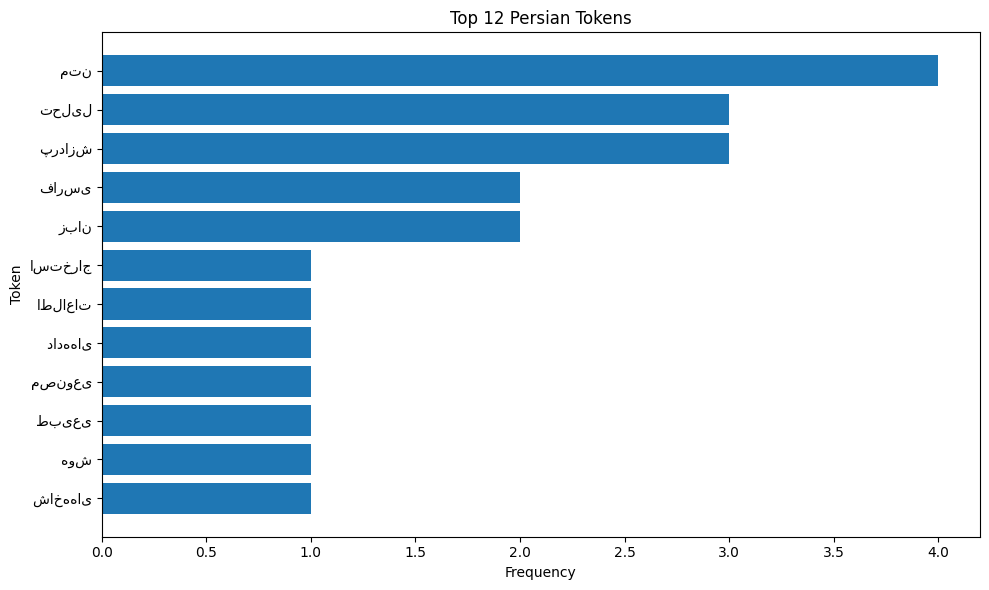

In [6]:
top_n = 12
top_tokens = frequency_df.head(top_n).sort_values("frequency")

plt.figure(figsize=(10, 6))
plt.barh(top_tokens["token"], top_tokens["frequency"])
plt.xlabel("Frequency")
plt.ylabel("Token")
plt.title(f"Top {min(top_n, len(frequency_df))} Persian Tokens")
plt.tight_layout()
plt.show()

## 7. Compare document lengths

Document length can be measured before or after filtering. Here we compare token counts after normalization and after stopword filtering.

In [7]:
length_df = pd.DataFrame({
    "document_id": range(1, len(documents) + 1),
    "tokens_before_filtering": [len(tokens) for tokens in tokenized_documents],
    "tokens_after_filtering": [len(tokens) for tokens in filtered_documents],
})

display(length_df)

,document_id,tokens_before_filtering,tokens_after_filtering
0,1,10,6
1,2,11,7
2,3,10,5
3,4,11,7
4,5,10,5
5,6,14,8


## 8. Build a reusable analysis function

A function makes it easier to apply the same workflow to a new list of documents.

In [8]:
def analyze_persian_documents(documents, top_n=20):
    normalized = [normalizer.normalize(doc) for doc in documents]
    tokenized = [word_tokenize(doc) for doc in normalized]
    filtered = [filter_tokens(tokens) for tokens in tokenized]

    counts = Counter(token for doc in filtered for token in doc)
    result = pd.DataFrame(counts.most_common(top_n), columns=["token", "frequency"])

    return {
        "normalized_documents": normalized,
        "tokenized_documents": tokenized,
        "filtered_documents": filtered,
        "frequencies": result,
    }

analysis_result = analyze_persian_documents(documents, top_n=15)
display(analysis_result["frequencies"])

,token,frequency
0,متن,4
1,پردازش,3
2,تحلیل,3
3,زبان,2
4,فارسی,2
5,طبیعی,1
6,شاخه‌های,1
7,هوش,1
8,مصنوعی,1
9,استخراج,1


## Interpretation and limitations

- This is a small illustrative corpus, so its frequency counts should not be treated as representative of Persian in general.
- Stopword lists can remove meaningful words; inspect them for the task.
- Character-range regular expressions may not cover every Persian-script mark or orthographic variant.
- For meaningful conclusions, use a larger, representative corpus and document preprocessing choices.

## Summary

This notebook combines normalization, tokenization, stopword filtering, frequency tables, and visualization into a reusable Persian text-analysis workflow.